# G1 RSS output — source feeds

Using data file: /home/user/g1/g1_articles.jsonl
Articles touched by each feed:
source_feeds
https://g1.globo.com/dynamo/pr/parana/rss2.xml                                    100
https://g1.globo.com/dynamo/pr/campos-gerais-sul/rss2.xml                         100
https://g1.globo.com/dynamo/ac/acre/rss2.xml                                      100
https://g1.globo.com/dynamo/am/amazonas/rss2.xml                                  100
https://g1.globo.com/dynamo/rss2.xml                                              100
https://g1.globo.com/dynamo/mg/centro-oeste/rss2.xml                              100
https://g1.globo.com/dynamo/rj/sul-do-rio-costa-verde/rss2.xml                    100
https://g1.globo.com/dynamo/carros/rss2.xml                                       100
https://g1.globo.com/dynamo/economia/rss2.xml                                     100
https://g1.globo.com/dynamo/rn/rio-grande-do-norte/rss2.xml                       100
https://g1.globo.com/dynamo/mundo/rss2.xml     

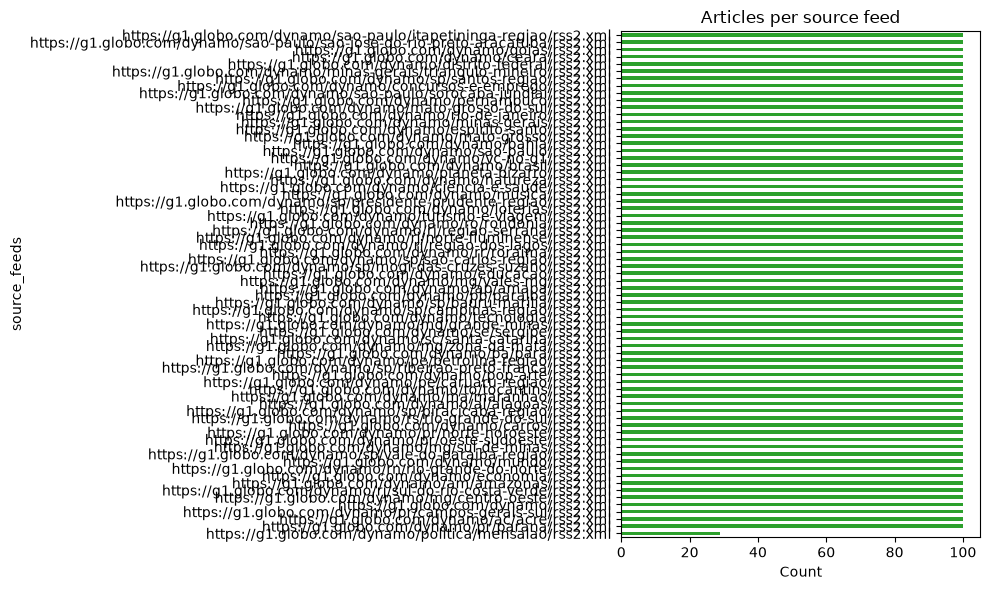

In [1]:

from pathlib import Path
import json

def find_data_file():
    candidates = [Path("g1_articles.jsonl"), Path("../g1_articles.jsonl"), Path("../../g1_articles.jsonl")]
    for c in candidates:
        if c.exists():
            return c
    for p in Path.cwd().rglob("g1_articles.jsonl"):
        return p
    raise FileNotFoundError("g1_articles.jsonl not found")

DATA_FILE = find_data_file()
print("Using data file:", DATA_FILE.resolve())

import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
rows = [json.loads(line) for line in DATA_FILE.read_text(encoding="utf-8").splitlines() if line.strip()]
df = pd.DataFrame(rows)
feed_counts = df["source_feeds"].explode().value_counts()
print("Articles touched by each feed:")
print(feed_counts.to_string())
print()
print("Multi-feed articles:", (df["source_feeds"].apply(len) > 1).sum())
fig, ax = plt.subplots(figsize=(10, 6))
feed_counts.sort_values().plot(kind="barh", ax=ax, color="#2ca02c")
ax.set_title("Articles per source feed")
ax.set_xlabel("Count")
plt.tight_layout()


In [2]:

from pathlib import Path
import json

def find_data_file():
    candidates = [Path("g1_articles.jsonl"), Path("../g1_articles.jsonl"), Path("../../g1_articles.jsonl")]
    for c in candidates:
        if c.exists():
            return c
    for p in Path.cwd().rglob("g1_articles.jsonl"):
        return p
    raise FileNotFoundError("g1_articles.jsonl not found")

DATA_FILE = find_data_file()
print("Using data file:", DATA_FILE.resolve())

import pandas as pd
rows = [json.loads(line) for line in DATA_FILE.read_text(encoding="utf-8").splitlines() if line.strip()]
df = pd.DataFrame(rows)
print("Distribution of number of source feeds per article:")
print(df["source_feeds"].apply(len).value_counts().sort_index().to_string())


Using data file: /home/user/g1/g1_articles.jsonl
Distribution of number of source feeds per article:
source_feeds
1     5716
2      346
3       57
4       74
5        4
6        1
7        2
14       1
